# Task 1A: Understanding the Dataset
**Group assignment:** Working with Time Series Data  
**Author:** David NGARAMBE (Member 1: exploratory analysis and preprocessing)

**Goal of this notebook:** describe the dataset, check its quality (time range, frequency, duplicates, gaps, missing values), decide how to handle each problem, and produce a clean hourly dataset that the rest of the group can use.

**Dataset:** Kaggle *Hourly Energy Consumption* (PJM), file `PJME_hourly.csv`, which holds hourly electricity demand for the PJM East region (US mid-Atlantic).  
**Second variable:** hourly air temperature for Philadelphia (Open-Meteo historical archive), added because the assignment requires *multiple measurable variables over time* and temperature is the main external driver of electricity demand.

## 1. Setup and loading the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Demand: original Kaggle file (two columns)
demand = pd.read_csv(RAW_DIR / "PJME_hourly.csv", parse_dates=["Datetime"])

# Temperature: Open-Meteo CSV has 3 metadata lines (location info + blank line) before the real header
temp = pd.read_csv(RAW_DIR / "philadelphia_temperature.csv", skiprows=3, parse_dates=["time"])
temp = temp.rename(columns={"time": "Datetime", "temperature_2m (°C)": "temperature_c"})

print("Demand shape:     ", demand.shape)
print("Temperature shape:", temp.shape)
demand.head()

Demand shape:      (145366, 2)
Temperature shape: (145416, 2)


,Datetime,PJME_MW
0,2002-12-31 01:00:00,"26,498.00"
1,2002-12-31 02:00:00,"25,147.00"
2,2002-12-31 03:00:00,"24,574.00"
3,2002-12-31 04:00:00,"24,393.00"
4,2002-12-31 05:00:00,"24,860.00"


In [3]:
demand.info()
temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[us]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.2 MB
<class 'pandas.DataFrame'>
RangeIndex: 145416 entries, 0 to 145415
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Datetime       145416 non-null  datetime64[us]
 1   temperature_c  145416 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.2 MB


### Column description

| Column | Source | Unit | Meaning |
|---|---|---|---|
| `Datetime` | both | local Eastern time, hourly | Timestamp of the reading |
| `PJME_MW` | PJM (Kaggle) | megawatts (MW) | Electricity demand of the PJM East region. **Prediction target** |
| `temperature_c` | Open-Meteo | degrees Celsius | Air temperature 2 m above ground in Philadelphia (39.96 N, 75.17 W) |

Philadelphia is used as one representative location for a region that spans several states. This is a simplification: real regional demand responds to the weather across the whole region, so the temperature signal will be somewhat noisier than a regional average.

## 2. Time range and frequency

In [4]:
print("Demand start:", demand["Datetime"].min())
print("Demand end:  ", demand["Datetime"].max())
span = demand["Datetime"].max() - demand["Datetime"].min()
print(f"Span: {span.days:,} days, about {span.days / 365.25:.1f} years")
print("Rows:", len(demand))
print("Already sorted by time?", demand["Datetime"].is_monotonic_increasing)

Demand start: 2002-01-01 01:00:00
Demand end:   2018-08-03 00:00:00
Span: 6,057 days, about 16.6 years
Rows: 145366
Already sorted by time? False


In [5]:
# Frequency: how far apart are consecutive timestamps (after sorting)?
demand_sorted = demand.sort_values("Datetime").reset_index(drop=True)
gaps = demand_sorted["Datetime"].diff().dropna()
gap_counts = gaps.value_counts().rename("count").to_frame()
gap_counts["share_%"] = gap_counts["count"] / gap_counts["count"].sum() * 100
gap_counts

,count,share_%
Datetime,,
0 days 01:00:00,145331,99.98
0 days 02:00:00,30,0.02
0 days 00:00:00,4,0.00


**Findings**
- The data runs from **2002-01-01 01:00 to 2018-08-03 00:00**, about **16.6 years**.
- The **frequency is hourly**: 99.98% of consecutive timestamps are exactly 1 hour apart.
- The raw file is **not in chronological order** (it starts in December 2002), so it must be sorted before any lag or rolling feature is computed.
- 30 jumps of 2 hours reveal missing hours, and 4 jumps of 0 hours reveal duplicated timestamps. Both are examined next.

## 3. Duplicates and missing timestamps

In [6]:
# 3a. Duplicate timestamps
dup_mask = demand_sorted["Datetime"].duplicated(keep=False)
print("Rows involved in duplicated timestamps:", dup_mask.sum())
demand_sorted[dup_mask]

Rows involved in duplicated timestamps: 8


,Datetime,PJME_MW
112487,2014-11-02 02:00:00,"23,755.00"
112488,2014-11-02 02:00:00,"22,935.00"
121223,2015-11-01 02:00:00,"21,567.00"
121224,2015-11-01 02:00:00,"21,171.00"
130127,2016-11-06 02:00:00,"20,795.00"
130128,2016-11-06 02:00:00,"21,692.00"
138863,2017-11-05 02:00:00,"21,236.00"
138864,2017-11-05 02:00:00,"20,666.00"


In [7]:
# 3b. Missing hours: compare against a complete hourly calendar
full_index = pd.date_range(demand_sorted["Datetime"].min(), demand_sorted["Datetime"].max(), freq="h")
missing = full_index.difference(pd.DatetimeIndex(demand_sorted["Datetime"].unique()))
print("Hours expected:", len(full_index), "| unique hours present:", demand_sorted["Datetime"].nunique(),
      "| missing hours:", len(missing))

def classify(ts):
    # US daylight saving time: clocks jump forward in Mar/Apr and fall back in Oct/Nov
    if ts.month in (3, 4) and ts.hour == 3:
        return "spring-forward (DST)"
    if ts.month in (10, 11) and ts.hour == 2:
        return "fall-back (DST)"
    return "genuine gap"

missing_df = pd.DataFrame({"Datetime": missing})
missing_df["type"] = missing_df["Datetime"].map(classify)
print(missing_df["type"].value_counts().to_string())
missing_df[missing_df["type"] == "genuine gap"]

Hours expected: 145392 | unique hours present: 145362 | missing hours: 30
type
spring-forward (DST)    17
fall-back (DST)         12
genuine gap              1


,Datetime,type
18,2010-12-10,genuine gap


**Findings**
- The 4 duplicates are all at **02:00 on the November daylight-saving "fall-back" day** (2014 to 2017): the clock hour happens twice, so two readings carry the same label.
- Of the 30 missing hours, **29 are daylight-saving effects**: 17 "spring-forward" hours (03:00 does not exist on that day, 2002 to 2018) and 12 "fall-back" hours from 2002 to 2013, where the repeated hour was not recorded.
- Only **one gap is genuine**: 2010-12-10 00:00.
- Together this means timestamps are in local clock time, so DST creates the irregularities. This is a data-recording artefact, not a real loss of electricity data.

### Missing values (NaN)

In [8]:
pd.DataFrame({"demand": demand.isna().sum(), "temperature": temp.isna().sum()}).T

,Datetime,PJME_MW,temperature_c
demand,0.00,0.00,NaN
temperature,0.00,NaN,0.00


Neither file contains empty (NaN) cells. All the problems are **structural**: unsorted rows, duplicate timestamps and absent hours, which were handled above.

## 4. Handling duplicates and missing values

Lag features (`lag_24`, `lag_168`) and rolling means only mean what they say if **one row = exactly one hour**. So the series is rebuilt on a complete hourly index:

1. **Duplicate timestamps** (2014 to 2017 fall-back hour): average the two readings, giving one row per hour.
2. **Missing hours** (DST hours and the single genuine gap): insert the empty rows, then fill them by **time-based linear interpolation**.
3. Every filled row is flagged in a new column `was_imputed` so it can be excluded or inspected later.

**Why interpolation?** Hourly demand is smooth, so neighbouring hours are very close to each other. Only 30 of about 145,000 hours (0.02%) are affected, and each gap is a single hour, so interpolation introduces almost no error. Dropping the rows would shift every lag by one hour after each gap, and forward-filling would copy a value from the wrong part of the daily cycle.

In [9]:
# 1) average duplicated timestamps
clean = demand_sorted.groupby("Datetime", as_index=False)["PJME_MW"].mean()

# 2) rebuild a complete hourly index and flag the rows we are about to create
clean = clean.set_index("Datetime").reindex(full_index)
clean.index.name = "Datetime"
clean["was_imputed"] = clean["PJME_MW"].isna()

# 3) fill each (single-hour) gap by linear interpolation in time
clean["PJME_MW"] = clean["PJME_MW"].interpolate(method="time")

print("Rows after rebuilding:", len(clean))
print("Imputed rows:", int(clean["was_imputed"].sum()))
print("Remaining NaN in PJME_MW:", int(clean["PJME_MW"].isna().sum()))
clean.loc[clean["was_imputed"]].head(8)

Rows after rebuilding: 145392
Imputed rows: 30
Remaining NaN in PJME_MW: 0


,PJME_MW,was_imputed
Datetime,,
2002-04-07 03:00:00,"24,612.50",True
2002-10-27 02:00:00,"21,714.00",True
2003-04-06 03:00:00,"23,123.50",True
2003-10-26 02:00:00,"21,822.00",True
2004-04-04 03:00:00,"23,354.50",True
2004-10-31 02:00:00,"21,806.00",True
2005-04-03 03:00:00,"23,577.00",True
2005-10-30 02:00:00,"24,462.50",True


In [10]:
# Add temperature (left join keeps exactly the demand hours)
clean = clean.reset_index().merge(temp, on="Datetime", how="left")
print("Rows without a temperature:", int(clean["temperature_c"].isna().sum()))
print("Shape:", clean.shape)
clean.head()

Rows without a temperature: 0
Shape: (145392, 4)


,Datetime,PJME_MW,was_imputed,temperature_c
0,2002-01-01 01:00:00,"30,393.00",False,-4.40
1,2002-01-01 02:00:00,"29,265.00",False,-4.70
2,2002-01-01 03:00:00,"28,357.00",False,-5.50
3,2002-01-01 04:00:00,"27,899.00",False,-5.90
4,2002-01-01 05:00:00,"28,057.00",False,-6.20


**Result:** the series now has **145,392 rows, exactly one per hour** from the first to the last timestamp. 30 values were interpolated (0.02%), flagged in `was_imputed`, and **no demand or temperature value is missing**.

## 5. Statistical summary of the numerical columns

In [11]:
num_cols = ["PJME_MW", "temperature_c"]
summary = clean[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
summary["skewness"] = clean[num_cols].skew()
summary["kurtosis"] = clean[num_cols].kurt()
summary

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
PJME_MW,"145,392.00","32,078.93","6,464.28","14,544.00","20,970.00","22,622.00","27,571.00","31,420.00","35,647.00","44,187.00","51,155.36","62,009.00",0.74,0.74
temperature_c,"145,392.00",12.86,10.29,-21.90,-9.20,-3.60,4.60,13.40,21.40,28.40,32.10,39.90,-0.15,-0.85


**Interpretation**
- **Demand:** mean 32,079 MW, median 31,420 MW, standard deviation 6,464 MW. The usual range (5th to 95th percentile) is 22,622 to 44,187 MW, while the extremes are 14,544 and 62,009 MW. The mean is above the median and the skewness is **+0.74**, so the distribution is **right-skewed**: occasional very high demand hours stretch the upper tail.
- **Temperature:** mean 12.9 °C, median 13.4 °C, standard deviation 10.3 °C, from -21.9 °C to 39.9 °C. Skewness is close to zero (-0.15) and kurtosis is negative (-0.85), so it is **flatter than a normal curve**: this is the typical shape of a variable that swings widely between cold winters and hot summers.

### Distributions

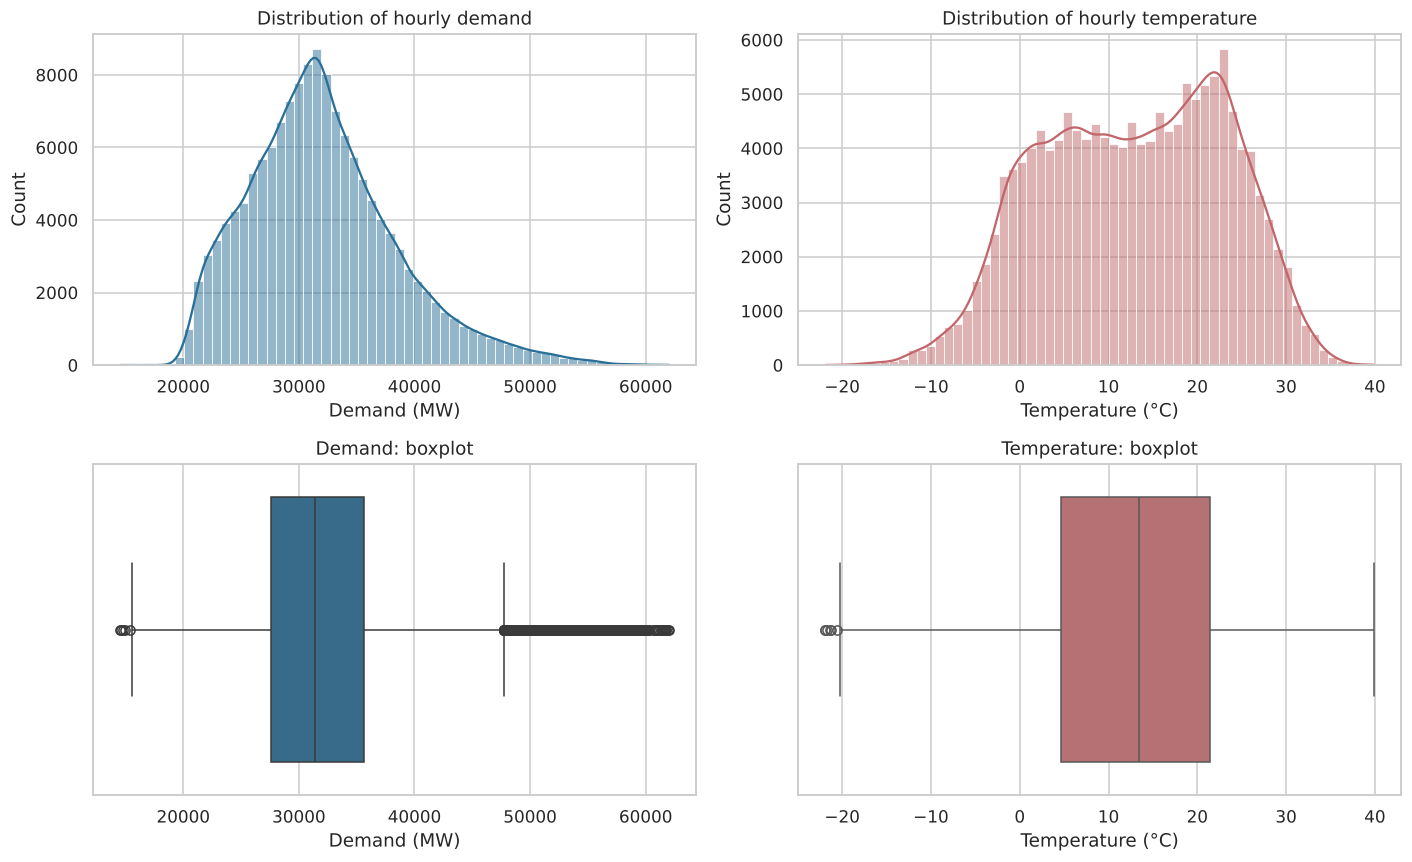

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

sns.histplot(clean["PJME_MW"], bins=60, kde=True, ax=axes[0, 0], color="#2a6f97")
axes[0, 0].set(title="Distribution of hourly demand", xlabel="Demand (MW)")

sns.histplot(clean["temperature_c"], bins=60, kde=True, ax=axes[0, 1], color="#c1666b")
axes[0, 1].set(title="Distribution of hourly temperature", xlabel="Temperature (°C)")

sns.boxplot(x=clean["PJME_MW"], ax=axes[1, 0], color="#2a6f97")
axes[1, 0].set(title="Demand: boxplot", xlabel="Demand (MW)")

sns.boxplot(x=clean["temperature_c"], ax=axes[1, 1], color="#c1666b")
axes[1, 1].set(title="Temperature: boxplot", xlabel="Temperature (°C)")

plt.tight_layout()
plt.show()

The demand histogram has one main hump around 28,000 to 35,000 MW with a long right tail. The boxplot confirms many points beyond the upper whisker. Temperature is spread broadly with no single sharp peak, reflecting the four seasons.

### Outliers

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, int(((s < lo) | (s > hi)).sum())

for col in num_cols:
    lo, hi, n = iqr_outliers(clean[col])
    print(f"{col:14s} IQR fences: [{lo:,.1f}, {hi:,.1f}]   outside fences: {n:,} ({n / len(clean) * 100:.2f}%)")

print("\nFive highest demand hours:")
clean.nlargest(5, "PJME_MW")[["Datetime", "PJME_MW", "temperature_c"]]

PJME_MW        IQR fences: [15,457.0, 47,761.0]   outside fences: 3,460 (2.38%)
temperature_c  IQR fences: [-20.6, 46.6]   outside fences: 6 (0.00%)

Five highest demand hours:


,Datetime,PJME_MW,temperature_c
40192,2006-08-02 17:00:00,"62,009.00",36.10
40191,2006-08-02 16:00:00,"61,909.00",35.90
40216,2006-08-03 17:00:00,"61,796.00",36.10
40215,2006-08-03 16:00:00,"61,770.00",36.10
83750,2011-07-22 15:00:00,"61,646.00",39.50


**Interpretation and decision**
- The IQR rule flags **3,460 demand hours (2.38%)**, almost all of them *above* 47,761 MW. About 98% of the high ones fall between **June and September**, and the five highest hours occurred during the **heat waves of August 2006 and July 2011**, at 36 to 39.5 °C. These are **real air-conditioning peaks, not errors**.
- The lowest demand (14,544 MW, 2012-10-30 at 04:00) falls on the date of Hurricane Sandy, which fits a storm-related drop in consumption.
- **Decision: keep all outliers.** They are genuine events, and a forecasting model should learn to handle peaks, since peaks are exactly when accurate prediction matters most for the grid. Removing them would make the model look better on average but fail when it counts.
- The 6 temperature outliers are real extreme-cold readings and are also kept.

## 6. Save the clean dataset for the group

In [14]:
out_path = PROCESSED_DIR / "pjme_clean.csv"
clean.to_csv(out_path, index=False)
print("Saved", out_path, clean.shape)
print("Columns:", list(clean.columns))

Saved ../data/processed/pjme_clean.csv (145392, 4)
Columns: ['Datetime', 'PJME_MW', 'was_imputed', 'temperature_c']


**Hand-off to the group:** `data/processed/pjme_clean.csv` contains `Datetime`, `PJME_MW`, `was_imputed` and `temperature_c`, with exactly one row per hour and no missing values. Task 1B (analytical questions and lag/moving-average features) builds on this file.